# Activity 7.01: Using Heatmaps to Find Patterns in Flight Passengers' Data

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

In [2]:
flights = pd.read_csv("flight_details.csv")
print(flights.shape)
print(flights.columns.tolist())
flights.head()

(144, 3)
['Years', 'Months', 'Passengers']


,Years,Months,Passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121


In [3]:
flight_table = flights.pivot(
    index="Months",
    columns="Years",
    values="Passengers"
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]
flight_table = flight_table.reindex(month_order)

print(flight_table.shape)
flight_table.head()

(12, 12)


Years,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
Months,,,,,,,,,,,,
January,112,115,145,171,196,204,242,284,315,340,360,417
February,118,126,150,180,196,188,233,277,301,318,342,391
March,132,141,178,193,236,235,267,317,356,362,406,419
April,129,135,163,181,235,227,269,313,348,348,396,461
May,121,125,172,183,229,234,270,318,355,363,420,472


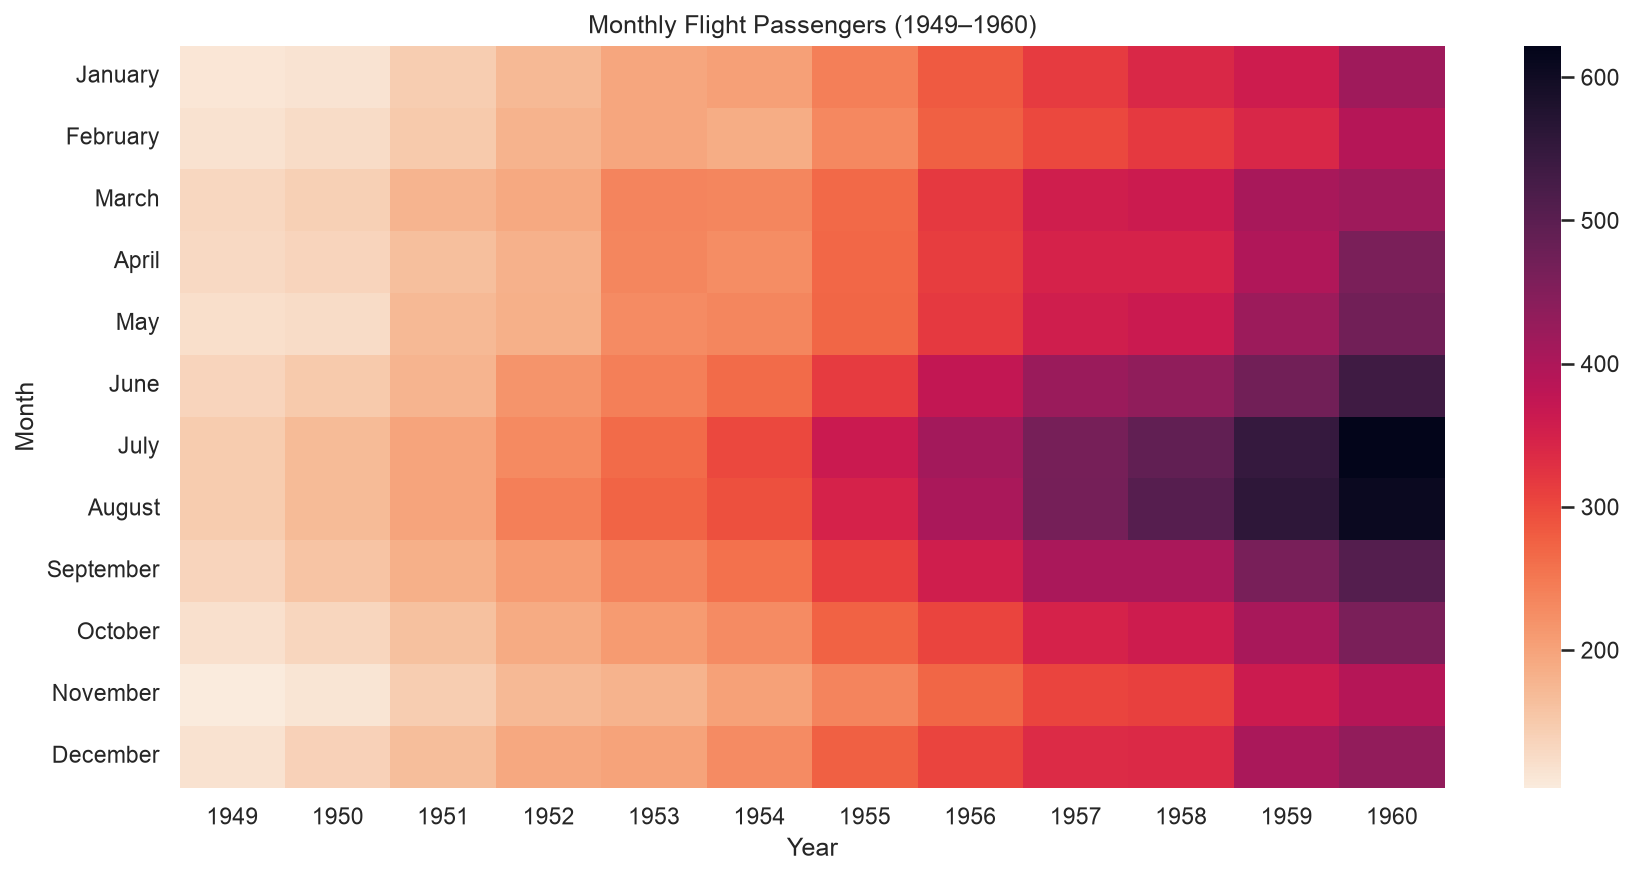

In [4]:
plt.figure(figsize=(12, 6), dpi=150)

sns.heatmap(
    flight_table,
    cmap="rocket_r"
)

plt.title("Monthly Flight Passengers (1949–1960)")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.savefig("passengers_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

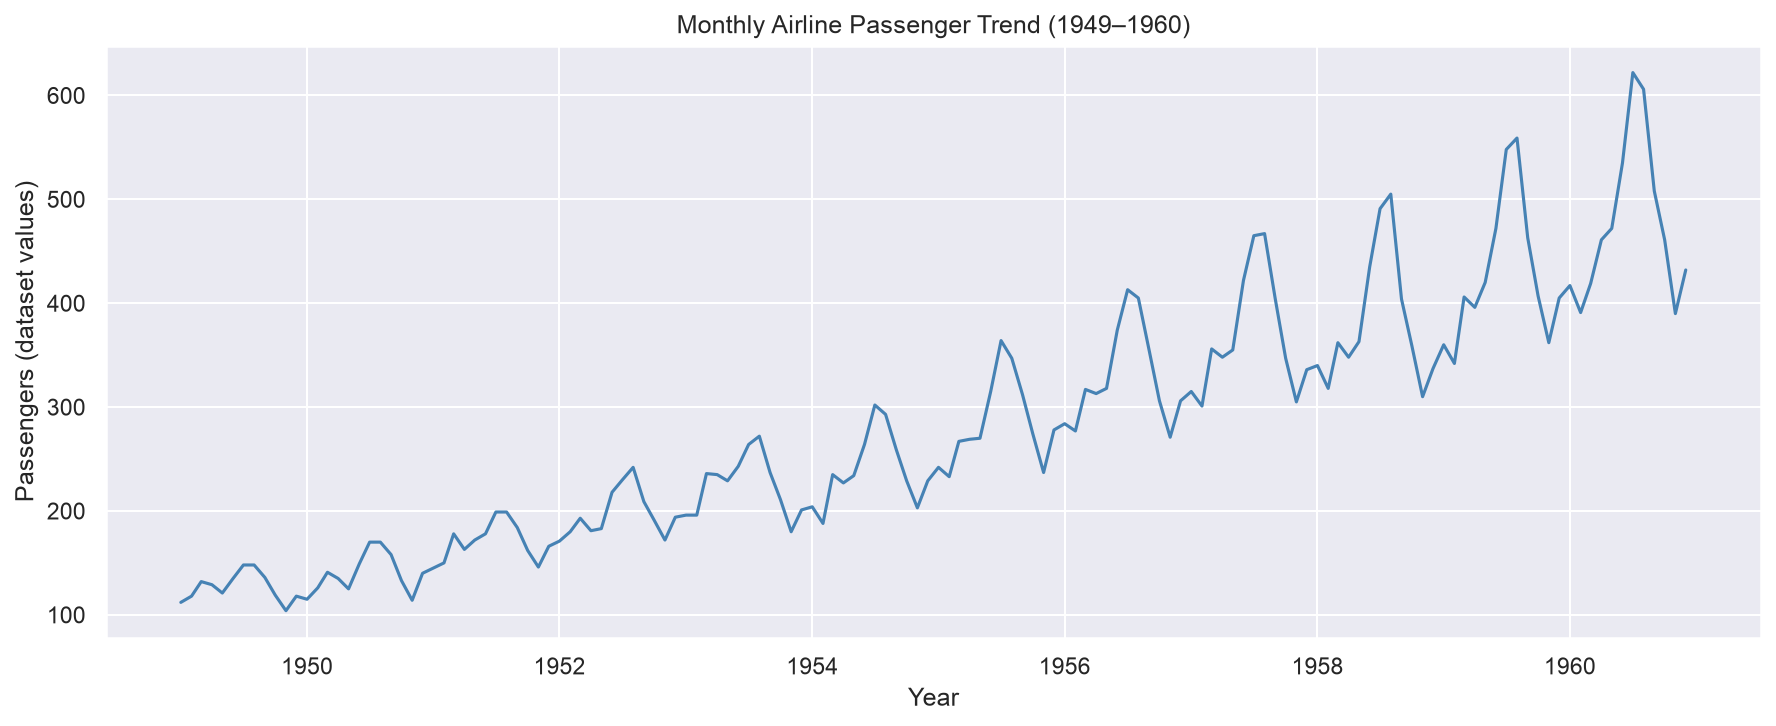

In [5]:
# Create dates and sort the observations chronologically
monthly = flights.copy()

monthly["Date"] = pd.to_datetime(
    monthly["Years"].astype(str) + "-" + monthly["Months"],
    format="%Y-%B"
)

monthly = monthly.sort_values("Date")

# Plot the long-term trend and seasonal fluctuations
plt.figure(figsize=(12, 5), dpi=150)

plt.plot(
    monthly["Date"],
    monthly["Passengers"],
    color="steelblue",
    linewidth=1.5
)

plt.title("Monthly Airline Passenger Trend (1949–1960)")
plt.xlabel("Year")
plt.ylabel("Passengers (dataset values)")
plt.tight_layout()

plt.savefig("passengers_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
requirements = """numpy==2.5.1
pandas==3.0.5
matplotlib==3.11.0
seaborn==0.13.2
jupyter
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("requirements.txt created")

requirements.txt created
